In [1]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit.quantum_info import entanglement_of_formation, DensityMatrix, Statevector

from functions import quantum_discord, make_channel, random_unitary

In [14]:
p_values = np.linspace(0, 1, 10)
rho0 = DensityMatrix.from_label('00')

avg_eof = []

for u in range(500):
    U1, U2 = random_unitary(2,method = "QR"), random_unitary(2,method = "QR")
    eof_values = []
    for p in p_values:
        channel = make_channel([U1, U2], p)
        rho_final = rho0.evolve(channel)
        entanglement = entanglement_of_formation(rho_final)
        eof_values.append(entanglement)
    avg_eof.append(np.mean(eof_values))

In [12]:
p_values = np.linspace(0, 1, 10)
rho0 = DensityMatrix.from_label('00')

avg_qd = []

for u in range(500):
    U1, U2 = random_unitary(2, method = "QR"), random_unitary(2, method = "QR")
    qd_values = []
    for p in p_values:
        channel = make_channel([U1, U2], p)
        rho_final = rho0.evolve(channel)
        qd = quantum_discord(rho_final)
        qd_values.append(qd)
    avg_qd.append(np.mean(qd_values))

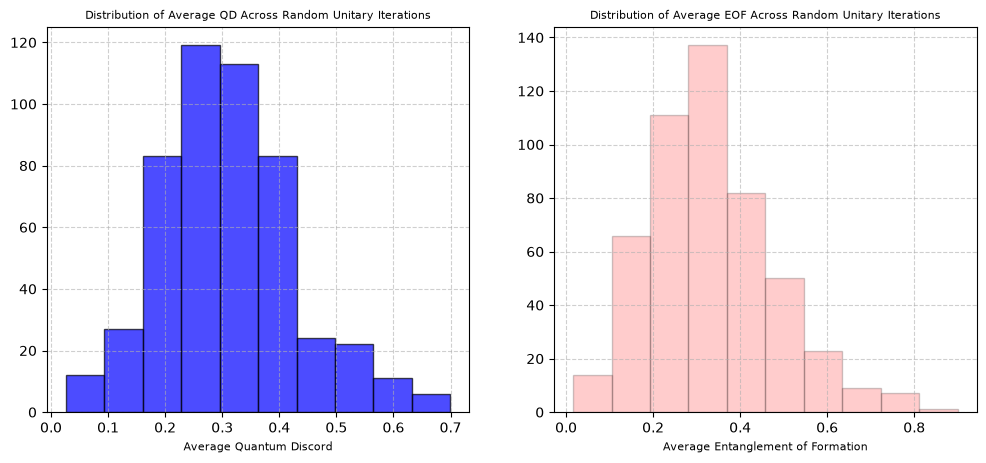

In [15]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(avg_qd, bins=10, color='blue', edgecolor='black', alpha=0.7, label = "QD")
plt.title('Distribution of Average QD Across Random Unitary Iterations', fontsize=8)
plt.xlabel('Average Quantum Discord', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.6)


plt.subplot(1,2,2)
plt.hist(avg_eof, bins=10, color='red', edgecolor='black', alpha=0.2, label = "EOF")
plt.title('Distribution of Average EOF Across Random Unitary Iterations', fontsize=8)
plt.xlabel('Average Entanglement of Formation', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.6)


plt.show()

## Amount of unitaries and correlations

In [2]:
from functions import make_random_channel

In [6]:
#start with a maximally entangled state
psi = Statevector.from_label('00') + Statevector.from_label('11')
rho0 = DensityMatrix(psi / np.sqrt(2))

N_unitaries = np.arange(2, 16)
eof_avgs = []
qd_avgs = []

for N in N_unitaries:
    eof_values = []
    qd_values =[]
    
    #loop over 100 different random channels
    for i in range(2000):
        #new random channel for each iteration
        channel = make_random_channel(n_unitaries=N, n_qubits=2, method="QR")
        
        # evolve and calculate
        rho_final = rho0.evolve(channel)
        eof_values.append(entanglement_of_formation(rho_final))
        qd_values.append(quantum_discord(rho_final))
        

    eof_avgs.append(np.mean(eof_values))
    qd_avgs.append(np.mean(qd_values))


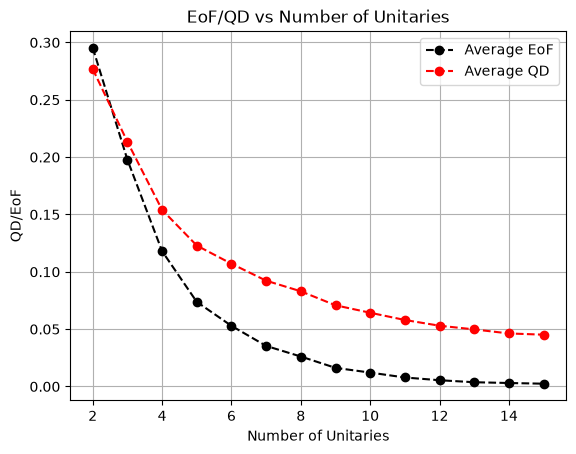

In [7]:
plt.plot(N_unitaries, eof_avgs,"o--",color = "black", label = "Average EoF")
plt.plot(N_unitaries, qd_avgs,"o--",color = "red", label = "Average QD")
plt.xlabel("Number of Unitaries"); plt.ylabel("QD/EoF"); plt.title("EoF/QD vs Number of Unitaries")
plt.legend(); plt.grid(); plt.show()